# Differential Operators on Spatial Graphs

**Estimated time**: 15-20 minutes

**Prerequisites**: [02: layouts](02_layout_engines.ipynb).

This notebook demonstrates the differential operator infrastructure for graph signal processing on spatial environments. These operators enable gradient-based analyses for reinforcement learning, replay analysis, and flow field computations.



## Learning Objectives

By the end of this notebook, you will be able to:

- Compute gradients of distance fields to create goal-directed flow fields
- Calculate divergence of flow fields to detect sources and sinks
- Apply Laplacian smoothing for graph-based spatial field processing
- Understand the differential operator matrix and its role in graph calculus
- Interpret flux divergence in a constructed set of shortest-path journeys

## Contents

1. **Gradient of Distance Fields** - Compute goal-directed flow from distance gradients
2. **Divergence of Flow Fields** - Detect sources and sinks in spatial trajectories
3. **Laplacian Smoothing** - Compare graph-based smoothing with Gaussian smoothing
4. **Journey Flux** - Verify sources, sinks and conservation on known paths

## Mathematical Background

Differential operators extend classical calculus to graph-structured environments:

- **Differential Operator** $D$: Fundamental matrix (n_bins × n_edges)
- **Gradient**: $\nabla f = D^T f$ (scalar field → edge field)
- **Divergence**: $\text{div}(g) = -M^{-1}D\,\mathrm{diag}(Ad)g$ (edge field → scalar field)
- **Laplacian**: $\text{div}(\text{grad}(f)) = -M^{-1}(\mathrm{Deg}-W)f$, with $W=A/d$

In [1]:
from itertools import pairwise

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np

from neurospatial import Environment
from neurospatial.ops.calculus import divergence, gradient
from neurospatial.ops.distance import distance_field

# Set random seed for reproducibility
np.random.seed(42)

## Setup: Create a 2D Environment

We'll create a rectangular environment for our demonstrations.

In [2]:
# Generate 2D random walk in open field arena
sampling_rate = 30.0  # Hz
duration = 60.0  # seconds
n_samples = int(duration * sampling_rate)

# Arena size: 100x100 cm open field
arena_size = 100.0  # cm
arena_center = arena_size / 2

# Random walk parameters
step_size = 2.5  # cm per step
boundary_margin = 5.0  # cm from walls

# Initialize trajectory
trajectory = np.zeros((n_samples, 2))
trajectory[0] = [arena_center, arena_center]  # Start at center

# Generate random walk with wall reflection
for i in range(1, n_samples):
    # Random step direction
    angle = np.random.uniform(0, 2 * np.pi)
    step = step_size * np.array([np.cos(angle), np.sin(angle)])

    # Propose new position
    new_pos = trajectory[i - 1] + step

    # Reflect at boundaries (with margin)
    for dim in range(2):
        if new_pos[dim] < boundary_margin:
            new_pos[dim] = boundary_margin + (boundary_margin - new_pos[dim])
        elif new_pos[dim] > (arena_size - boundary_margin):
            new_pos[dim] = (arena_size - boundary_margin) - (
                new_pos[dim] - (arena_size - boundary_margin)
            )

    trajectory[i] = new_pos

# Define the full known arena, independently of where this walk sampled.
# Orthogonal edges have shared faces of length 5 cm.
arena_edges = np.linspace(0.0, arena_size, 21)
env = Environment.from_grid_mask(
    np.ones((20, 20), dtype=bool),
    (arena_edges, arena_edges),
    connect_diagonal_neighbors=False,
)
env.units = "cm"
env.frame = "arena"

print("Environment created:")
print(f"  Arena: {arena_size:.0f}x{arena_size:.0f} cm open field")
print(f"  Bins: {env.n_bins}")
print(f"  Edges: {env.connectivity.number_of_edges()}")
print(f"  Dimensions: {env.n_dims}D")
print(
    f"  Spatial coverage: X=[{trajectory[:, 0].min():.1f}, {trajectory[:, 0].max():.1f}], Y=[{trajectory[:, 1].min():.1f}, {trajectory[:, 1].max():.1f}] cm"
)

Environment created:
  Arena: 100x100 cm open field
  Bins: 400
  Edges: 760
  Dimensions: 2D
  Spatial coverage: X=[46.7, 95.0], Y=[5.2, 94.9] cm


## Part 1: Gradient of Distance Fields

The **gradient operator** transforms a scalar field (values at bins) into an edge field (values on edges).

### Mathematical Definition

$$\nabla f = D^T f$$

where $D$ has coefficients $-1/d$ and $+1/d$ on each oriented edge. The gradient is $(f_j-f_i)/d$, in field units per cm here.

### Physical Interpretation

For each edge:
- **Positive gradient**: Field increases along edge (uphill)
- **Negative gradient**: Field decreases along edge (downhill)
- **Zero gradient**: Field is constant

### Application: Goal-Directed Navigation

Negative edge gradients identify neighboring bins with lower distance.
They are local graph directions, not an inferred continuous animal velocity.

In [3]:
# Define goal bin (use a bin near the center of environment)
# Find bin closest to center of bin_centers
center_of_env = env.bin_centers.mean(axis=0)
distances_to_center = np.linalg.norm(env.bin_centers - center_of_env, axis=1)
goal_bin = int(np.argmin(distances_to_center))

print(f"Goal bin index: {goal_bin}")
print(f"Goal bin position: {env.bin_centers[goal_bin]}")

# Compute distance field from goal
distances = distance_field(env.connectivity, sources=[goal_bin])

# Compute gradient (edge field)
grad_distances = gradient(env, distances)

print(f"Distance field shape: {distances.shape}  (scalar field, n_bins)")
print(f"Gradient shape: {grad_distances.shape}  (edge field, n_edges)")
print(f"Gradient range: [{grad_distances.min():.2f}, {grad_distances.max():.2f}]")

Goal bin index: 189
Goal bin position: [47.5 47.5]
Distance field shape: (400,)  (scalar field, n_bins)
Gradient shape: (760,)  (edge field, n_edges)
Gradient range: [-1.00, 1.00]


### Visualizing the Gradient Field

We'll visualize:
- **Left**: Distance field (scalar field at nodes)
- **Right**: Gradient magnitude (mapped to nodes for visualization)

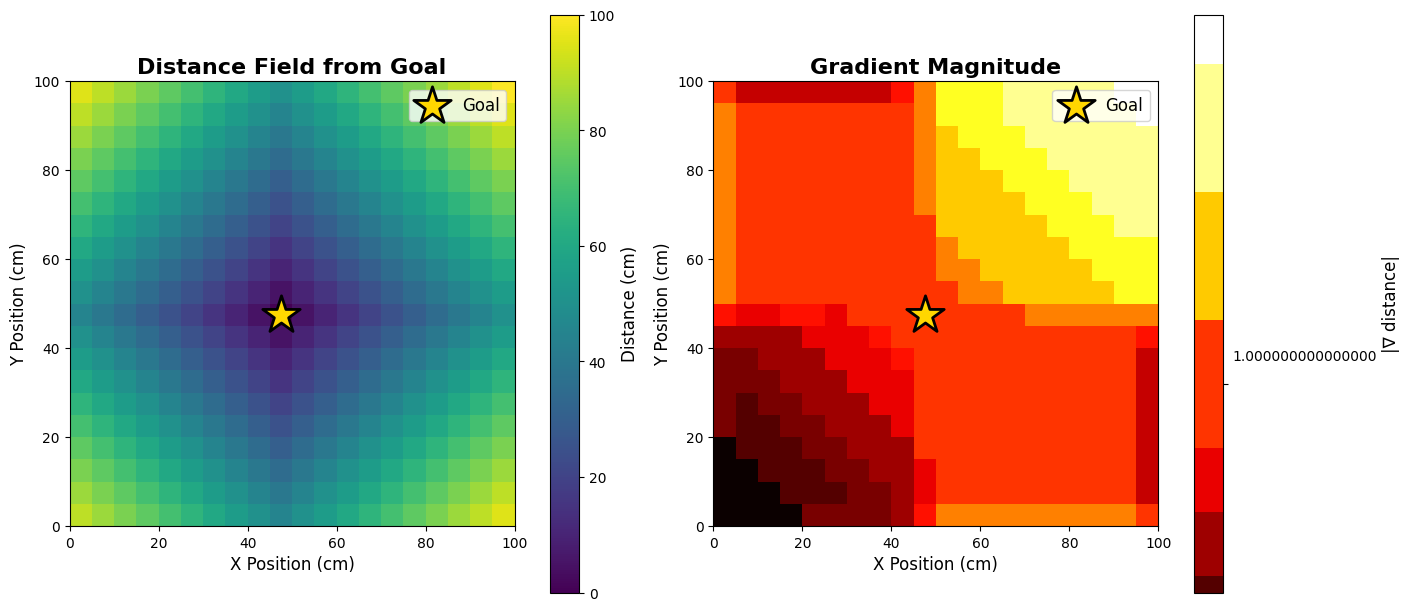

In [4]:
# Map edge gradients to nodes (average over incident edges)
grad_magnitude = np.abs(grad_distances)
grad_per_node = np.zeros(env.n_bins)
degree = np.zeros(env.n_bins)

for edge_id, (u, v) in enumerate(env.connectivity.edges()):
    grad_per_node[u] += grad_magnitude[edge_id]
    grad_per_node[v] += grad_magnitude[edge_id]
    degree[u] += 1
    degree[v] += 1

grad_per_node /= np.maximum(degree, 1)

# Plotting with scientific presentation style
fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)

# Distance field
ax = axes[0]
env.plot_field(
    distances,
    ax=ax,
    cmap="viridis",
    colorbar_label="Distance (cm)",
)
ax.scatter(
    env.bin_centers[goal_bin, 0],
    env.bin_centers[goal_bin, 1],
    marker="*",
    s=800,
    c="gold",
    edgecolors="black",
    linewidths=2,
    label="Goal",
    zorder=10,
)
ax.set_title("Distance Field from Goal", fontsize=16, fontweight="bold")
ax.legend(fontsize=12, loc="upper right")

# Gradient magnitude
ax = axes[1]
env.plot_field(
    grad_per_node,
    ax=ax,
    cmap="hot",
    colorbar_label="|∇ distance|",
)
ax.scatter(
    env.bin_centers[goal_bin, 0],
    env.bin_centers[goal_bin, 1],
    marker="*",
    s=800,
    c="gold",
    edgecolors="black",
    linewidths=2,
    label="Goal",
    zorder=10,
)
ax.set_title("Gradient Magnitude", fontsize=16, fontweight="bold")
ax.legend(fontsize=12, loc="upper right")

plt.show()

**Interpretation**:
- **Left panel**: Distance increases away from goal (purple = close, yellow = far)
- **Right panel**: Gradient magnitude shows steepness of distance change (red = steep, dark = flat)
- A distance field has approximately unit slope along shortest-path directions;
  its gradient need not become steeper near the goal.

## Part 2: Divergence of Flow Fields

The **divergence operator** transforms an edge field (values on edges) into a scalar field (values at bins).

### Mathematical Definition

$$\text{div}(g) = -M^{-1}D\,\mathrm{diag}(Ad)g$$

where $g$ is an edge flux density, $A$ is the shared-face measure, and $M$ is the cell volume.

### Physical Interpretation

For each bin:
- **Positive divergence**: Net outflow (source) - flow originates here
- **Negative divergence**: Net inflow (sink) - flow terminates here
- **Zero divergence**: Conservation - inflow equals outflow

### Application: Source and Sink Detection

Treat the negative gradient as a constructed flux density. Its divergence
depends on geometry and boundary conditions; it is not an estimate of
occupancy-weighted animal flow or a transition probability.

In [5]:
# Create goal-directed flow field (negative gradient points toward goal)
goal_directed_flow = -grad_distances

# Compute divergence (net outflow from each bin)
div_flow = divergence(env, goal_directed_flow)

print(f"Flow field shape: {goal_directed_flow.shape}  (edge field)")
print(f"Divergence shape: {div_flow.shape}  (scalar field)")
print(f"Divergence range: [{div_flow.min():.3f}, {div_flow.max():.3f}]")
print(f"\nGoal bin divergence: {div_flow[goal_bin]:.3f}  (should be negative - sink)")

# Identify source and sink bins
sources = np.where(div_flow > 0.05)[0]
sinks = np.where(div_flow < -0.05)[0]

print(f"\nSource bins (divergence > 0.05): {len(sources)}")
print(f"Sink bins (divergence < -0.05): {len(sinks)}")

Flow field shape: (760,)  (edge field)
Divergence shape: (400,)  (scalar field)
Divergence range: [-0.800, 0.400]

Goal bin divergence: -0.800  (should be negative - sink)

Source bins (divergence > 0.05): 72
Sink bins (divergence < -0.05): 39


### Visualizing Flow Divergence

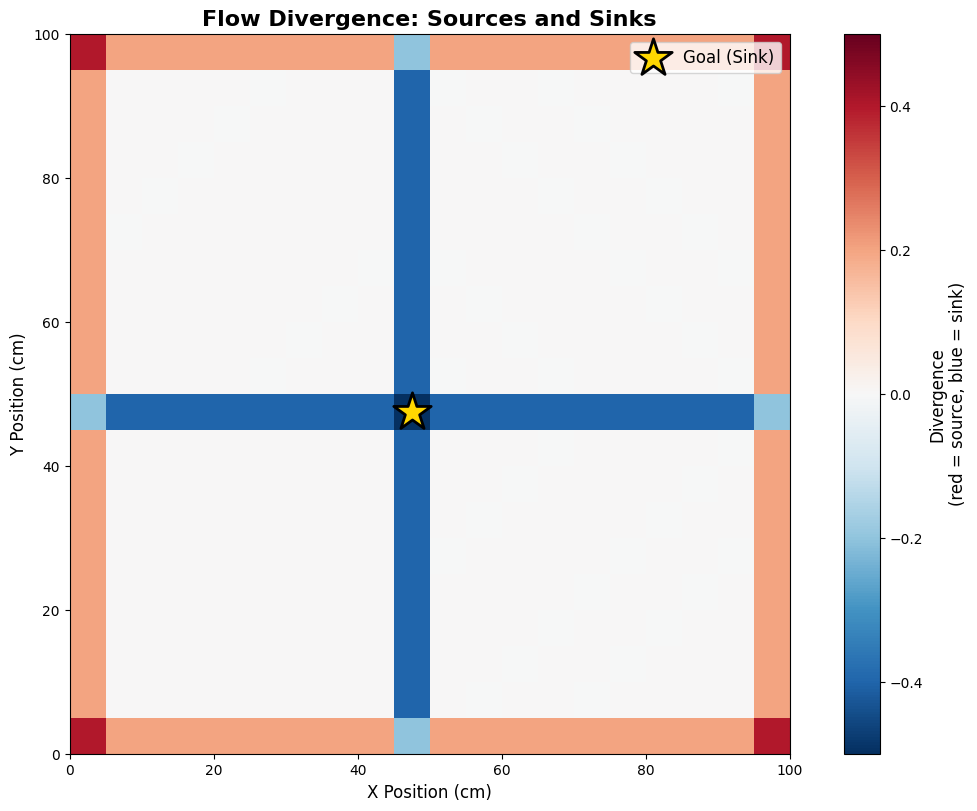

In [6]:
fig, ax = plt.subplots(figsize=(10, 8), constrained_layout=True)

# Divergence field with symmetric colormap
env.plot_field(
    div_flow,
    ax=ax,
    cmap="RdBu_r",
    vmin=-0.5,
    vmax=0.5,
    colorbar_label="Divergence\n(red = source, blue = sink)",
)

# Mark goal (should be a sink)
ax.scatter(
    env.bin_centers[goal_bin, 0],
    env.bin_centers[goal_bin, 1],
    marker="*",
    s=800,
    c="gold",
    edgecolors="black",
    linewidths=2,
    label="Goal (Sink)",
    zorder=10,
)

ax.set_title("Flow Divergence: Sources and Sinks", fontsize=16, fontweight="bold")
ax.legend(fontsize=12, loc="upper right")

plt.show()

**Interpretation**:
- **Blue bins (negative divergence)**: Flow terminates here (sinks) - includes goal location
- **Red bins (positive divergence)**: Local net outflow under this constructed flux
- **White bins (zero divergence)**: Conservation - equal inflow and outflow
- Goal bin is the strongest sink (most negative divergence)

## Part 3: Laplacian Smoothing

The **Laplacian operator** is the composition of divergence and gradient:

$$\nabla^2 f \approx \text{div}(\text{grad}(f)) = -M^{-1}(\mathrm{Deg}-W)f$$

### Physical Interpretation

The Laplacian measures how much a bin's value differs from its neighbors:
- **Positive Laplacian**: Bin value is lower than neighbors (local minimum)
- **Negative Laplacian**: Bin value is higher than neighbors (local maximum)
- **Zero Laplacian**: Bin value equals average of neighbors (harmonic)

### Application: Graph-Based Smoothing

Iteratively applying $f \leftarrow f + \alpha\,\text{div}(\text{grad}(f))$ smooths a field via heat diffusion on the graph. The step $\alpha$ is in cm² and must be below $2/\lambda_{max}$ (a conservative bound is $h^2/4$ on a uniform 2-D grid).

In [7]:
# Create a noisy field
np.random.seed(42)
noisy_field = np.random.randn(env.n_bins)


def laplacian_smooth(field, env, alpha=1.0, n_iterations=50):
    """Smooth field via iterative Laplacian (heat diffusion)."""
    smoothed = field.copy()

    for _ in range(n_iterations):
        # Compute Laplacian: L(f) = div(grad(f))
        grad_field = gradient(env, smoothed)
        laplacian = divergence(env, grad_field)

        # Heat equation: f_new = f + alpha * div(grad(f))
        smoothed = smoothed + alpha * laplacian

    return smoothed


# Apply Laplacian smoothing
alpha = 1.0  # cm squared; below h^2 / 4 for this 5 cm orthogonal grid
n_iterations = 50
laplacian_smoothed = laplacian_smooth(
    noisy_field, env, alpha=alpha, n_iterations=n_iterations
)

# Match heat time t = n_iterations * alpha to bandwidth sigma = sqrt(2*t).
# mode="average" preserves an intensive field and its constant baseline.
bandwidth = np.sqrt(2 * alpha * n_iterations)
gaussian_smoothed = env.smooth(noisy_field, bandwidth=bandwidth, mode="average")
np.testing.assert_allclose(gaussian_smoothed.mean(), noisy_field.mean(), atol=1e-12)

print(f"Original field std: {noisy_field.std():.3f}")
print(f"Laplacian smoothed std: {laplacian_smoothed.std():.3f}")
print(f"Gaussian smoothed std: {gaussian_smoothed.std():.3f}")

Original field std: 0.959
Laplacian smoothed std: 0.149
Gaussian smoothed std: 0.150


### Comparing Smoothing Methods

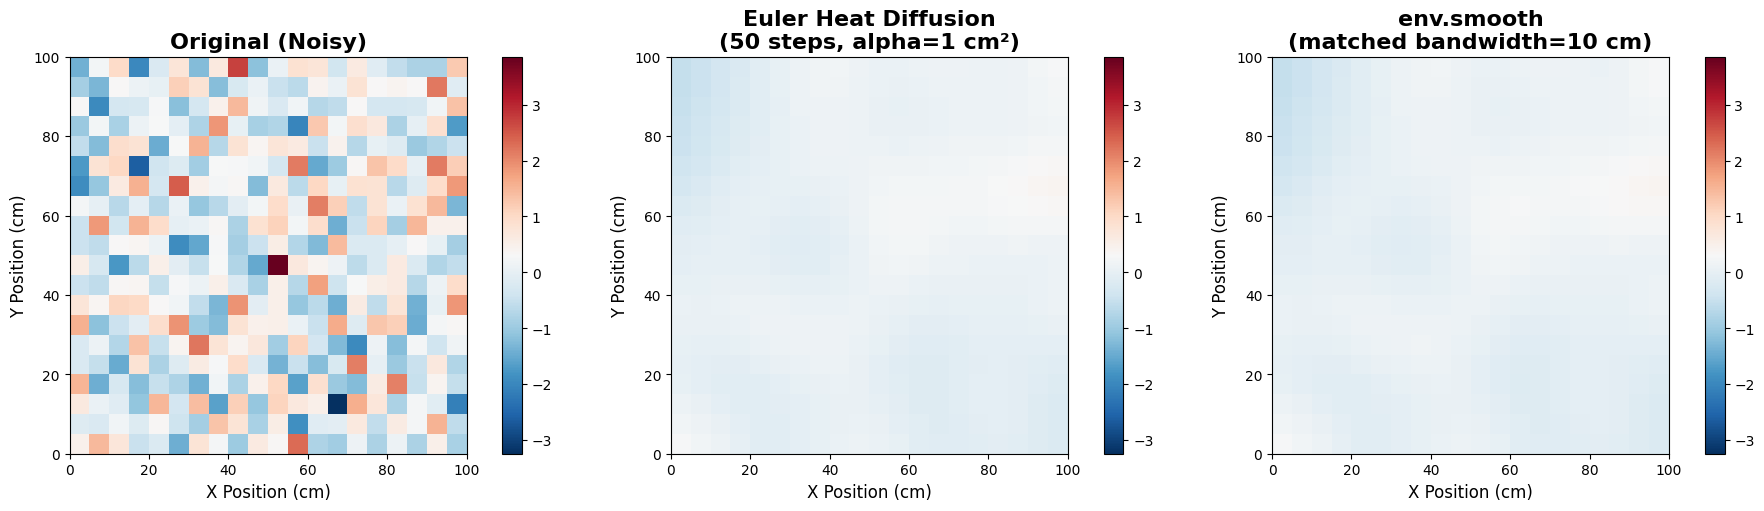

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)

# Determine common color limits
vmin = min(noisy_field.min(), laplacian_smoothed.min(), gaussian_smoothed.min())
vmax = max(noisy_field.max(), laplacian_smoothed.max(), gaussian_smoothed.max())

# Original noisy field
ax = axes[0]
env.plot_field(
    noisy_field,
    ax=ax,
    cmap="RdBu_r",
    vmin=vmin,
    vmax=vmax,
)
ax.set_title("Original (Noisy)", fontsize=16, fontweight="bold")

# Laplacian smoothed
ax = axes[1]
env.plot_field(
    laplacian_smoothed,
    ax=ax,
    cmap="RdBu_r",
    vmin=vmin,
    vmax=vmax,
)
ax.set_title(
    "Euler Heat Diffusion\n(50 steps, alpha=1 cm²)", fontsize=16, fontweight="bold"
)

# Gaussian smoothed
ax = axes[2]
env.plot_field(
    gaussian_smoothed,
    ax=ax,
    cmap="RdBu_r",
    vmin=vmin,
    vmax=vmax,
)
ax.set_title("env.smooth\n(matched bandwidth=10 cm)", fontsize=16, fontweight="bold")

plt.show()

**Interpretation**:
- **Left**: Original noisy field with high variance
- **Middle**: Laplacian smoothing via iterative heat diffusion
- **Right**: The built-in heat operator at the same nominal diffusion time
- Both use the same finite-volume geometry. Euler steps approximate the
  exponential heat operator; reducing the step improves their agreement.

### Verification: Mathematical Correctness

Verify the continuum identity ∇²(x² + y²) = 4 in interior bins.
The physical Laplacian is the negative of the finite-volume diffusion generator.

In [9]:
edges = np.arange(21, dtype=float)
check_env = Environment.from_grid_mask(np.ones((20, 20), bool), (edges, edges))
check_env.units = "cm"
test_field = np.sum(check_env.bin_centers**2, axis=1)
laplacian_ours = divergence(check_env, gradient(check_env, test_field))
interior = np.array([degree == 8 for _, degree in check_env.connectivity.degree()])
np.testing.assert_allclose(laplacian_ours[interior], 4.0, atol=1e-12)
print(f"Interior ∇²(x² + y²): {np.mean(laplacian_ours[interior]):.6f} (expected 4)")
assert laplacian_smoothed.var() < noisy_field.var()

Interior ∇²(x² + y²): 4.000000 (expected 4)


## Part 4: Flux from Constructed Shortest-Path Journeys

Choose starts and route each one to a common goal using the graph's shortest
paths. These are synthetic journeys, not recorded behavior, a learned policy,
a successor representation or detected replay. Signed edge traversal counts
conserve flow at intermediate bins. Dividing by face length converts counts
to the flux density required by `divergence`.

Routed 50 synthetic journeys to goal bin 315
Goal divergence: -0.0400 per cm² per journey
Volume-weighted divergence equals starts minus arrivals, with zero total.


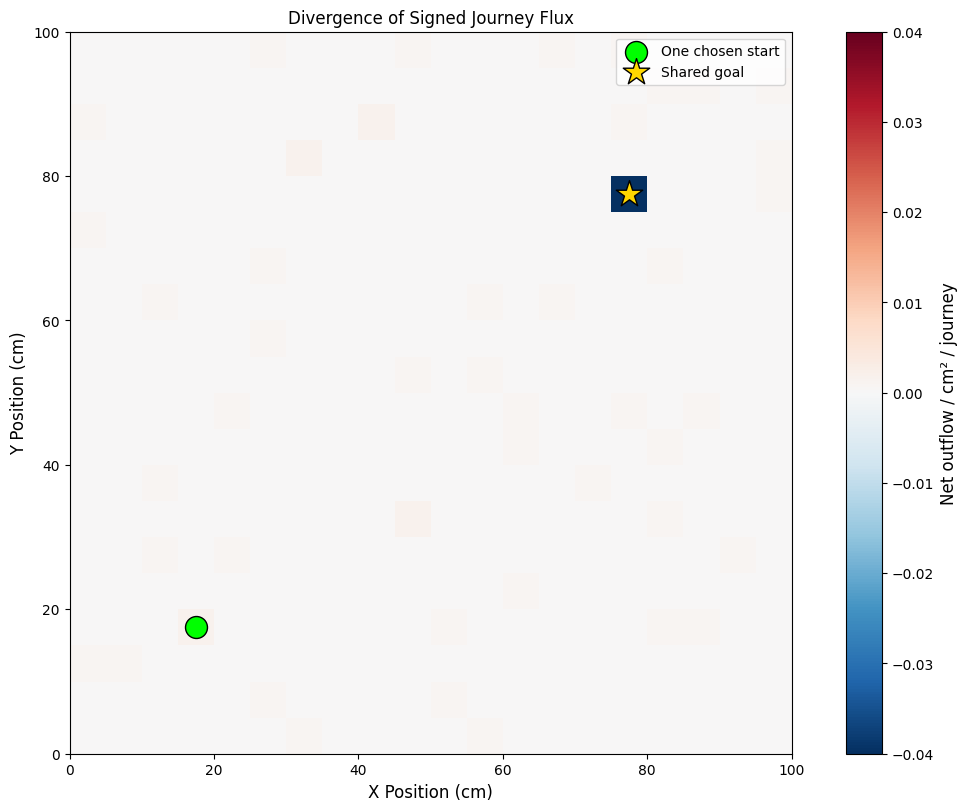

In [10]:
start_bin = int(np.argmin(np.linalg.norm(env.bin_centers - [20.0, 20.0], axis=1)))
goal_bin = int(np.argmin(np.linalg.norm(env.bin_centers - [80.0, 80.0], axis=1)))
journey_rng = np.random.default_rng(7)
n_journeys = 50
available_starts = np.setdiff1d(np.arange(env.n_bins), [goal_bin])
journey_starts = journey_rng.choice(available_starts, size=n_journeys)
journey_starts[0] = start_bin

edge_order = list(env.connectivity.edges())
edge_lookup = {frozenset((u, v)): (i, u, v) for i, (u, v) in enumerate(edge_order)}
signed_counts = np.zeros(len(edge_order))
for source in journey_starts:
    path = nx.shortest_path(env.connectivity, int(source), goal_bin, weight="distance")
    for u, v in pairwise(path):
        edge_id, oriented_u, _ = edge_lookup[frozenset((u, v))]
        signed_counts[edge_id] += 1.0 if u == oriented_u else -1.0

# The known square grid has 5 cm faces and 25 cm² cells (no diagonal fluxes).
face_length = 5.0
journey_flux = signed_counts / (n_journeys * face_length)
div_journeys = divergence(env, journey_flux)
expected_net = np.bincount(journey_starts, minlength=env.n_bins) / n_journeys
expected_net[goal_bin] -= 1.0
np.testing.assert_allclose(div_journeys * env.bin_sizes, expected_net, atol=1e-12)
np.testing.assert_allclose(np.dot(div_journeys, env.bin_sizes), 0.0, atol=1e-12)
print(f"Routed {n_journeys} synthetic journeys to goal bin {goal_bin}")
print(f"Goal divergence: {div_journeys[goal_bin]:.4f} per cm² per journey")
print("Volume-weighted divergence equals starts minus arrivals, with zero total.")

fig, ax = plt.subplots(figsize=(10, 8), constrained_layout=True)
limit = float(np.max(np.abs(div_journeys)))
env.plot_field(
    div_journeys,
    ax=ax,
    cmap="RdBu_r",
    vmin=-limit,
    vmax=limit,
    colorbar_label="Net outflow / cm² / journey",
)
ax.scatter(
    *env.bin_centers[start_bin],
    marker="o",
    s=250,
    c="lime",
    edgecolors="black",
    label="One chosen start",
    zorder=10,
)
ax.scatter(
    *env.bin_centers[goal_bin],
    marker="*",
    s=400,
    c="gold",
    edgecolors="black",
    label="Shared goal",
    zorder=10,
)
ax.set_title("Divergence of Signed Journey Flux")
ax.legend()
plt.show()

The shared goal is a sink. Starts are sources, and bins traversed without
starting or stopping conserve net flux. Geometry and the chosen journeys
determine this example; applying it to recordings requires appropriate
observation windows and a justified conversion from transitions to flux.

## Summary

This notebook demonstrated differential operators on spatial graphs:

### Key Concepts

1. **Gradient** ($\nabla f = D^T f$): Scalar field → edge field (rate of change along edges)
2. **Divergence** ($\text{div}(g) = -M^{-1}D\,\mathrm{diag}(Ad)g$): Edge field → scalar field (net outflow from nodes)
3. **Laplacian** ($\nabla^2 f \approx -M^{-1}(\mathrm{Deg}-W)f$): Smoothness measure (difference from neighbors)

### Applications

- **Constructed navigation fields**: Negative distance gradients identify downhill edges
- **Source/sink detection**: Divergence of signed face flux gives net local outflow
- **Graph smoothing**: Laplacian diffusion → alternative to Gaussian smoothing
- **Journey analysis**: Check sources and sinks of explicitly supplied paths

### When to Use Differential Operators

- Analyzing **policy gradients** in RL tasks
- Detecting **flow patterns** in replay sequences
- Implementing **custom smoothing** algorithms
- Computing **spatial derivatives** of neural fields
- Studying **diffusion processes** on graphs

### Further Reading

- Shuman et al. (2013): *The Emerging Field of Signal Processing on Graphs*
- Stachenfeld et al. (2017): *The Hippocampus as a Predictive Map*
- Pfeiffer & Foster (2013): *Hippocampal Place-Cell Sequences Depict Future Paths*

## Next Steps

Continue to [10: signal processing](10_signal_processing_primitives.ipynb)
for neighborhood statistics and custom kernels.